# Analyse de sentiment d'avis clients : iPhone 14

Comparaison de deux modèles d'analyse de sentiment (VADER et TextBlob) sur les avis d'un modèle de téléphone, avec nuages de mots et matrices de confusion.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Mobile Reviews Sentiment(in).csv")

In [3]:
# Aperçu des données (sans les noms des clients)
df.drop(columns=["customer_name"]).head(30)

,review_id,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,review_text,...,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,review_length,word_count,helpful_votes,source
0,1,45,Realme,Realme 12 Pro,337.31,₹27996.73,INR,83.00,2,Not worth the money spent. Wouldn’t recommend.,...,True,1,1,3,2,1,46,7,1,Amazon
1,2,18,Realme,Realme 12 Pro,307.78,R$1754.35,BRL,5.70,4,Absolutely love this phone! The camera is next...,...,True,3,2,4,3,2,74,12,5,Flipkart
2,3,27,Google,Pixel 6,864.53,₹71755.99,INR,83.00,4,Loving the clean UI and fast updates. Loving i...,...,True,3,5,3,2,4,55,11,8,AliExpress
3,4,19,Xiaomi,Redmi Note 13,660.94,د.إ2425.65,AED,3.67,3,Build quality feels solid and durable. No regr...,...,False,1,3,2,1,2,66,11,3,Amazon
4,5,38,Motorola,Edge 50,792.13,R$4515.14,BRL,5.70,3,Not bad for daily use but could be optimized. ...,...,True,3,3,2,2,1,73,12,0,BestBuy
5,6,38,Apple,iPhone 14,948.79,R$5408.1,BRL,5.70,5,Battery easily lasts a day with heavy use. No ...,...,False,5,4,5,5,4,70,13,6,AliExpress
6,7,40,OnePlus,OnePlus 12,420.13,د.إ1541.88,AED,3.67,3,Loving the clean UI and fast updates. Absolute...,...,False,3,3,2,1,2,58,10,2,eBay
7,8,39,Apple,iPhone SE,1443.76,A$2208.95,AUD,1.53,2,"Phone hangs often, regret buying it. Wouldn’t ...",...,True,2,1,2,2,2,56,8,3,Amazon
8,9,32,Realme,Realme 12 Pro,275.73,€256.43,EUR,0.93,4,Battery easily lasts a day with heavy use. Lov...,...,False,4,3,2,3,3,60,12,8,eBay
9,10,31,OnePlus,OnePlus Nord 3,545.57,A$834.72,AUD,1.53,3,Smooth performance even after months of use. N...,...,True,2,2,3,3,2,72,12,4,BestBuy


In [4]:
# On garde les colonnes utiles à notre analyse
df = df[['brand', 'model','rating', 'review_text', 'sentiment']]

In [5]:
# Filtre sur votre modèle 
mask = df["model"] == "iPhone 14"
df = df[mask]
df.head()

,brand,model,rating,review_text,sentiment
5,Apple,iPhone 14,5,Battery easily lasts a day with heavy use. No ...,Positive
36,Apple,iPhone 14,4,Battery easily lasts a day with heavy use. Lov...,Positive
45,Apple,iPhone 14,2,"Does what it’s supposed to, nothing special. A...",Neutral
51,Apple,iPhone 14,1,Camera quality is very poor indoors. Not up to...,Negative
62,Apple,iPhone 14,3,Fast charging is a lifesaver. No regrets buyin...,Positive


In [6]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text



In [7]:
df["clean_text"] = df["review_text"].apply(clean_text)
df.head()

,brand,model,rating,review_text,sentiment,clean_text
5,Apple,iPhone 14,5,Battery easily lasts a day with heavy use. No ...,Positive,battery easily lasts a day with heavy use no r...
36,Apple,iPhone 14,4,Battery easily lasts a day with heavy use. Lov...,Positive,battery easily lasts a day with heavy use lovi...
45,Apple,iPhone 14,2,"Does what it’s supposed to, nothing special. A...",Neutral,does what its supposed to nothing special aver...
51,Apple,iPhone 14,1,Camera quality is very poor indoors. Not up to...,Negative,camera quality is very poor indoors not up to ...
62,Apple,iPhone 14,3,Fast charging is a lifesaver. No regrets buyin...,Positive,fast charging is a lifesaver no regrets buying...


In [8]:
valeur = df['sentiment'].value_counts()


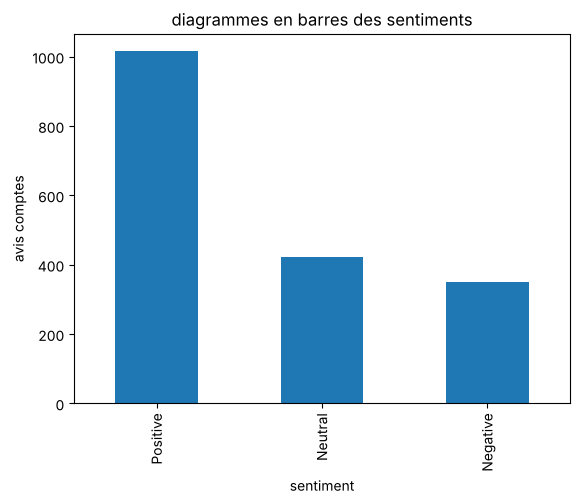

In [9]:
import matplotlib.pyplot as plt
valeur.plot.bar()
plt.title("diagrammes en barres des sentiments")
plt.xlabel('sentiment')
plt.ylabel('avis comptes')
plt.show()

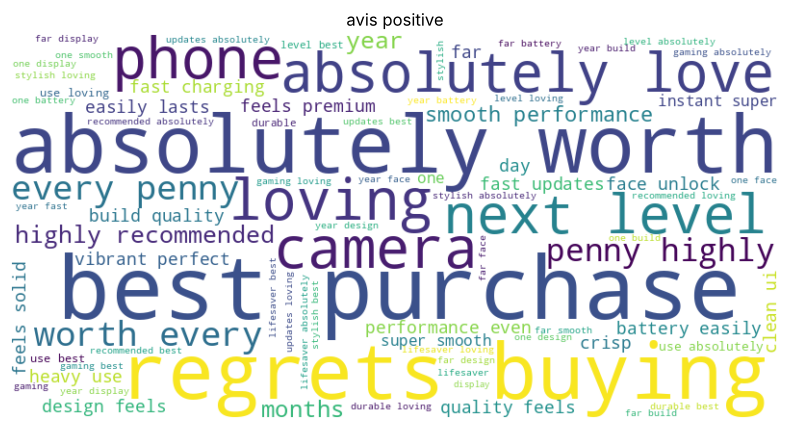

In [10]:
# le wordcloud positive
from wordcloud import WordCloud

#text = ' '.join(df['sentiment'].astype(str).apply(''.join, axis=1))
text = ' '.join(df[df['sentiment'] == 'Positive']['clean_text'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('avis positive')
plt.axis('off')
plt.show()

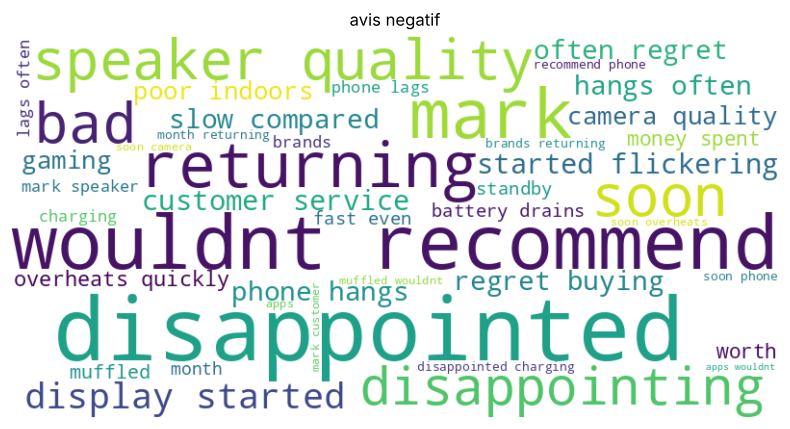

In [11]:
text_1 = ' '.join(df[df['sentiment'] == 'Negative']['clean_text'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text_1)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('avis negatif')
plt.axis('off')
plt.show()

# le  modèle vader

In [12]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()
df['compound'] = df['review_text'].apply( lambda x: sia.polarity_scores(x)["compound"])
df.head()


,brand,model,rating,review_text,sentiment,clean_text,compound
5,Apple,iPhone 14,5,Battery easily lasts a day with heavy use. No ...,Positive,battery easily lasts a day with heavy use no r...,-0.3182
36,Apple,iPhone 14,4,Battery easily lasts a day with heavy use. Lov...,Positive,battery easily lasts a day with heavy use lovi...,0.7644
45,Apple,iPhone 14,2,"Does what it’s supposed to, nothing special. A...",Neutral,does what its supposed to nothing special aver...,-0.3089
51,Apple,iPhone 14,1,Camera quality is very poor indoors. Not up to...,Negative,camera quality is very poor indoors not up to ...,-0.5256
62,Apple,iPhone 14,3,Fast charging is a lifesaver. No regrets buyin...,Positive,fast charging is a lifesaver no regrets buying...,0.0258


In [13]:
score = [-0.5 , 0.5]
def fonc_classi(compoud, score):
    if compoud < score[0]:
        return 'Negative'
    elif compoud > score[1]:
        return 'Positive'
    else:
        return 'Neutral'
    
df['sentiment_predi'] = df['compound'].apply(lambda x: fonc_classi(x, score))
df


,brand,model,rating,review_text,sentiment,clean_text,compound,sentiment_predi
5,Apple,iPhone 14,5,Battery easily lasts a day with heavy use. No ...,Positive,battery easily lasts a day with heavy use no r...,-0.3182,Neutral
36,Apple,iPhone 14,4,Battery easily lasts a day with heavy use. Lov...,Positive,battery easily lasts a day with heavy use lovi...,0.7644,Positive
45,Apple,iPhone 14,2,"Does what it’s supposed to, nothing special. A...",Neutral,does what its supposed to nothing special aver...,-0.3089,Neutral
51,Apple,iPhone 14,1,Camera quality is very poor indoors. Not up to...,Negative,camera quality is very poor indoors not up to ...,-0.5256,Negative
62,Apple,iPhone 14,3,Fast charging is a lifesaver. No regrets buyin...,Positive,fast charging is a lifesaver no regrets buying...,0.0258,Neutral
...,...,...,...,...,...,...,...,...
49824,Apple,iPhone 14,4,Build quality feels solid and durable. Loving ...,Positive,build quality feels solid and durable loving i...,0.6996,Positive
49826,Apple,iPhone 14,3,Build quality feels solid and durable. Absolut...,Positive,build quality feels solid and durable absolute...,0.4740,Neutral
49844,Apple,iPhone 14,3,Not worth the money spent. Not up to the mark.,Negative,not worth the money spent not up to the mark,-0.1695,Neutral
49952,Apple,iPhone 14,2,Phone lags often after a few apps. Wouldn’t re...,Negative,phone lags often after a few apps wouldnt reco...,0.0000,Neutral


In [14]:
from sklearn.metrics import classification_report, confusion_matrix

cm = confusion_matrix(df['sentiment'], df['sentiment_predi'])
print(classification_report(df['sentiment'], df['sentiment_predi']))


              precision    recall  f1-score   support

    Negative       0.62      0.37      0.46       350
     Neutral       0.31      0.50      0.38       423
    Positive       0.80      0.70      0.75      1015

    accuracy                           0.59      1788
   macro avg       0.57      0.52      0.53      1788
weighted avg       0.65      0.59      0.61      1788



## Interprétons les valeurs calculées avec VADER

Pour les avis positifs : une précision de 80 % signifie que, parmi les avis prédits positifs, 80 % étaient vraiment positifs. Un recall de 70 % signifie que sur tous les avis réellement positifs, 70 % ont été retrouvés. Le f1-score de 75 % donne une bonne moyenne entre la précision et le recall.

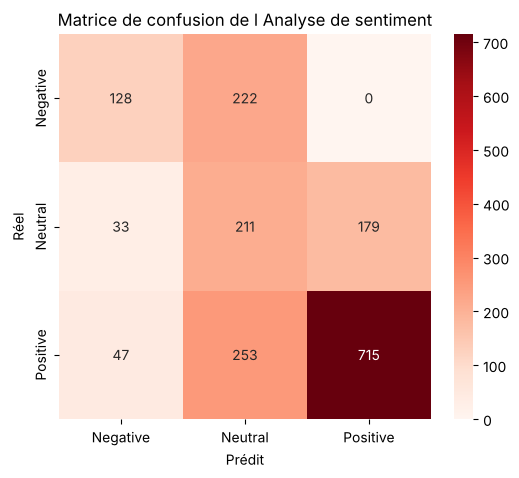

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',cmap="Reds",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"])
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.title('Matrice de confusion de l Analyse de sentiment')
plt.show()


## Interprétation de la matrice de confusion VADER

Pour les avis négatifs : 128 ont été bien prédits sur 350, les autres ont été mal prédits comme neutres (222).

Pour les avis neutres : 211 ont été bien prédits sur 423, les autres ont été mal prédits comme positifs (179) ou négatifs (33).

Pour les avis positifs : 715 ont été bien prédits sur 1 015, les autres ont été mal prédits comme neutres (253) ou négatifs (47).

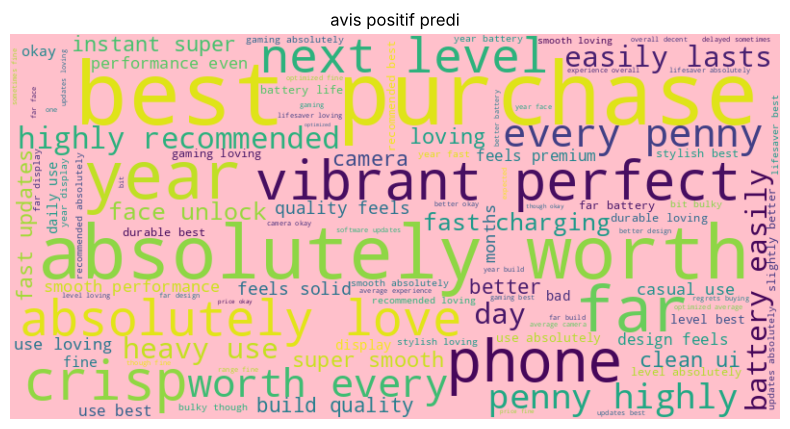

In [16]:
text_prdi = ' '.join(df[df['sentiment_predi'] == 'Positive']['clean_text'])
wordcloud = WordCloud(width=800, height=400, background_color='pink').generate(text_prdi)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('avis positif predi')
plt.axis('off')
plt.show()

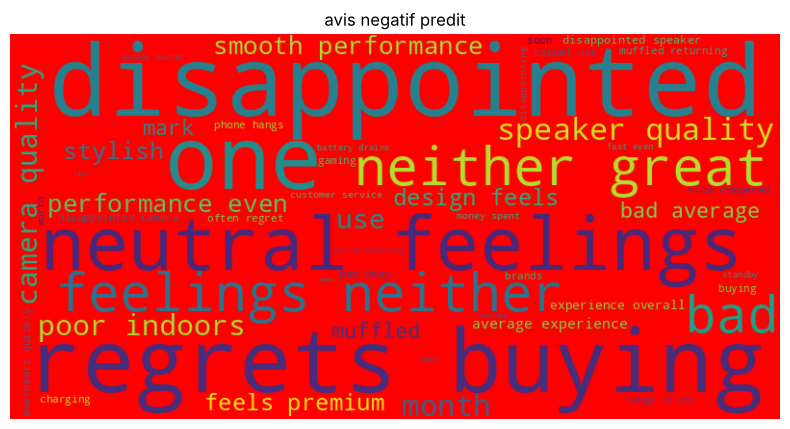

In [17]:
text_prdi_2 = ' '.join(df[df['sentiment_predi'] == 'Negative']['clean_text'])
wordcloud = WordCloud(width=800, height=400, background_color='red').generate(text_prdi_2)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('avis negatif predit')
plt.axis('off')
plt.show()

# le modele textblob

In [18]:
import textblob
from textblob import TextBlob

df['text_blob_polarity'] = df['clean_text'].apply(lambda x: round(TextBlob(x).sentiment.polarity,4))
df['text_blob_subjectivity'] = df['clean_text'].apply(lambda x: TextBlob(x).sentiment.subjectivity)
df


,brand,model,rating,review_text,sentiment,clean_text,compound,sentiment_predi,text_blob_polarity,text_blob_subjectivity
5,Apple,iPhone 14,5,Battery easily lasts a day with heavy use. No ...,Positive,battery easily lasts a day with heavy use no r...,-0.3182,Neutral,0.0944,0.511111
36,Apple,iPhone 14,4,Battery easily lasts a day with heavy use. Lov...,Positive,battery easily lasts a day with heavy use lovi...,0.7644,Positive,0.2333,0.820833
45,Apple,iPhone 14,2,"Does what it’s supposed to, nothing special. A...",Neutral,does what its supposed to nothing special aver...,-0.3089,Neutral,0.0690,0.323810
51,Apple,iPhone 14,1,Camera quality is very poor indoors. Not up to...,Negative,camera quality is very poor indoors not up to ...,-0.5256,Negative,-0.5200,0.780000
62,Apple,iPhone 14,3,Fast charging is a lifesaver. No regrets buyin...,Positive,fast charging is a lifesaver no regrets buying...,0.0258,Neutral,0.1250,0.400000
...,...,...,...,...,...,...,...,...,...,...
49824,Apple,iPhone 14,4,Build quality feels solid and durable. Loving ...,Positive,build quality feels solid and durable loving i...,0.6996,Positive,0.2333,0.683333
49826,Apple,iPhone 14,3,Build quality feels solid and durable. Absolut...,Positive,build quality feels solid and durable absolute...,0.4740,Neutral,0.1500,0.100000
49844,Apple,iPhone 14,3,Not worth the money spent. Not up to the mark.,Negative,not worth the money spent not up to the mark,-0.1695,Neutral,-0.1250,0.100000
49952,Apple,iPhone 14,2,Phone lags often after a few apps. Wouldn’t re...,Negative,phone lags often after a few apps wouldnt reco...,0.0000,Neutral,-0.2000,0.100000


In [19]:
df["tb_polarity"] = df["review_text"].astype(str).apply(
    lambda x: TextBlob(x).sentiment.polarity
)

In [20]:
def classifi_(tb_polarity, score_tb = 0.1):
    if tb_polarity > score_tb:
        return "Positive"
    elif tb_polarity < - score_tb:
        return "Negative"
    else:
        return "Neutral"
df['sentiment-textbob'] = df['tb_polarity'].apply(lambda x : classifi_(x , score_tb= 0.1))
df

,brand,model,rating,review_text,sentiment,clean_text,compound,sentiment_predi,text_blob_polarity,text_blob_subjectivity,tb_polarity,sentiment-textbob
5,Apple,iPhone 14,5,Battery easily lasts a day with heavy use. No ...,Positive,battery easily lasts a day with heavy use no r...,-0.3182,Neutral,0.0944,0.511111,0.094444,Neutral
36,Apple,iPhone 14,4,Battery easily lasts a day with heavy use. Lov...,Positive,battery easily lasts a day with heavy use lovi...,0.7644,Positive,0.2333,0.820833,0.239583,Positive
45,Apple,iPhone 14,2,"Does what it’s supposed to, nothing special. A...",Neutral,does what its supposed to nothing special aver...,-0.3089,Neutral,0.0690,0.323810,0.069048,Neutral
51,Apple,iPhone 14,1,Camera quality is very poor indoors. Not up to...,Negative,camera quality is very poor indoors not up to ...,-0.5256,Negative,-0.5200,0.780000,-0.520000,Negative
62,Apple,iPhone 14,3,Fast charging is a lifesaver. No regrets buyin...,Positive,fast charging is a lifesaver no regrets buying...,0.0258,Neutral,0.1250,0.400000,0.125000,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...
49824,Apple,iPhone 14,4,Build quality feels solid and durable. Loving ...,Positive,build quality feels solid and durable loving i...,0.6996,Positive,0.2333,0.683333,0.241667,Positive
49826,Apple,iPhone 14,3,Build quality feels solid and durable. Absolut...,Positive,build quality feels solid and durable absolute...,0.4740,Neutral,0.1500,0.100000,0.187500,Positive
49844,Apple,iPhone 14,3,Not worth the money spent. Not up to the mark.,Negative,not worth the money spent not up to the mark,-0.1695,Neutral,-0.1250,0.100000,-0.125000,Negative
49952,Apple,iPhone 14,2,Phone lags often after a few apps. Wouldn’t re...,Negative,phone lags often after a few apps wouldnt reco...,0.0000,Neutral,-0.2000,0.100000,-0.200000,Negative


In [21]:
cm_tb = confusion_matrix(df['sentiment'], df['sentiment-textbob'])
print(classification_report(df['sentiment'], df['sentiment-textbob']))


              precision    recall  f1-score   support

    Negative       1.00      0.71      0.83       350
     Neutral       0.60      0.37      0.46       423
    Positive       0.76      0.95      0.84      1015

    accuracy                           0.77      1788
   macro avg       0.79      0.68      0.71      1788
weighted avg       0.77      0.77      0.75      1788



## Interprétons le résultat pour les avis négatifs (TextBlob)

- Une précision de 100 % signifie que, parmi les avis prédits négatifs, tous étaient vraiment négatifs.
- Un recall de 71 % signifie que, parmi les avis réellement négatifs, 71 % ont été retrouvés.
- Un f1-score de 83 % donne une bonne moyenne entre la précision et le recall : c'est un bon score.

On fait la même lecture pour les avis positifs et neutres.

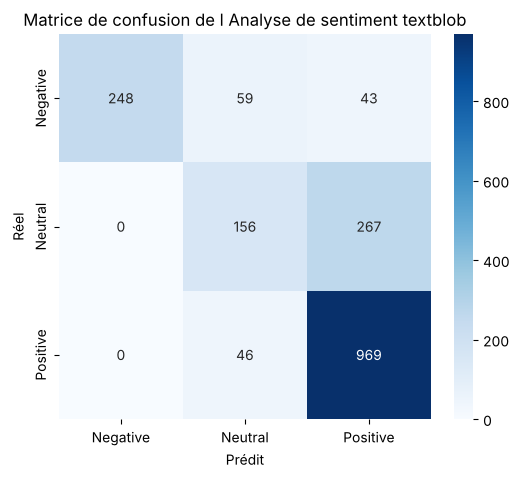

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
sns.heatmap(cm_tb, annot=True, fmt='d',cmap="Blues",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"])
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.title('Matrice de confusion de l Analyse de sentiment textblob')
plt.show()


## Interprétation de la matrice de confusion TextBlob

Pour les avis négatifs : 248 ont été bien prédits sur 350. Aucun avis d'une autre classe n'a été prédit négatif, mais tous les avis négatifs n'ont pas été retrouvés (59 prédits neutres et 43 positifs).

Pour les avis neutres : 156 ont été bien prédits sur 423, les autres ont été mal prédits comme positifs (267).

Pour les avis positifs : 969 ont été bien prédits sur 1 015, les autres ont été mal prédits comme neutres (46).

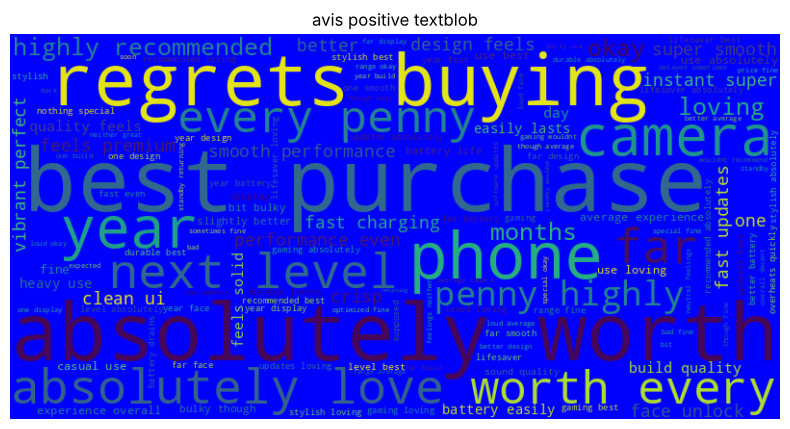

In [23]:
text_prdi_3 = ' '.join(df[df['sentiment-textbob'] == 'Positive']['clean_text'])
wordcloud = WordCloud(width=800, height=400, background_color='blue').generate(text_prdi_3)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('avis positive textblob')
plt.axis('off')
plt.show()

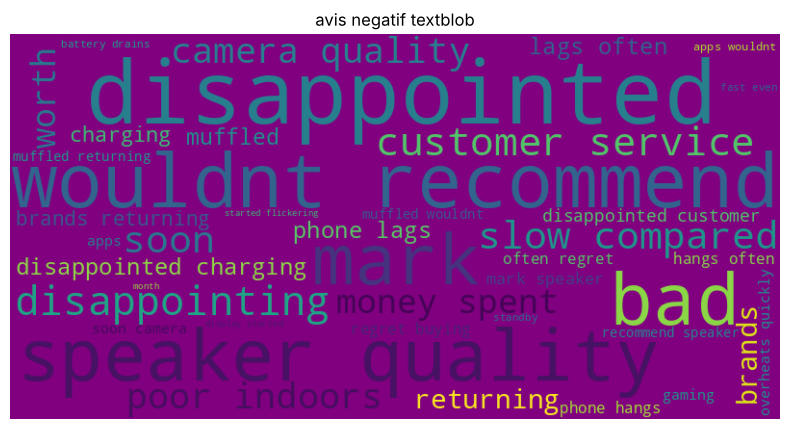

In [24]:
text_prdi_4 = ' '.join(df[df['sentiment-textbob'] == 'Negative']['clean_text'])
wordcloud = WordCloud(width=800, height=400, background_color='purple').generate(text_prdi_4)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('avis negatif textblob')
plt.axis('off')
plt.show()

## Conclusion générale sur les deux modèles

Après ces analyses, on retient que TextBlob est plus efficace dans l'ensemble : il retrouve beaucoup mieux les avis positifs et négatifs. VADER a plus de mal à classer correctement les avis : il range beaucoup d'avis positifs et négatifs dans la classe neutre, et il retrouve peu d'avis négatifs.

TextBlob a une accuracy de 77 % alors que VADER a une accuracy de 59 %.

La matrice de confusion va dans le même sens : avec TextBlob, la plupart des avis sont à la bonne place, ce qui est moins le cas avec VADER.

TextBlob retrouve 71 % des avis négatifs et 95 % des avis positifs, alors que VADER en retrouve 37 % et 70 %.

Pour les avis neutres, les deux modèles ont du mal : VADER en retrouve davantage (recall de 50 % contre 37 %) mais se trompe souvent (précision de 31 % contre 60 % pour TextBlob).

Ces conclusions tiennent compte des seuils de neutralité choisis (±0,5 pour VADER, ±0,1 pour TextBlob), qui ne sont pas identiques.

**Pour conclure :** TextBlob est plus efficace que VADER sur ce jeu de données, et on l'a montré de plusieurs manières. L'iPhone 14 compte aussi plus d'avis positifs que d'avis négatifs, y compris selon la prédiction des modèles.